# 07 — Machine Learning : analyse prédictive de la gravité

## Projet final Data Analyst — Accidents routiers BAAC 2020-2024

### Objectif

Développer un modèle de classification permettant d'identifier
les situations associées à une gravité élevée des accidents routiers.

### Problématique

Dans quelle mesure les caractéristiques des accidents,
les conditions de circulation, les infrastructures et les
profils des usagers permettent-ils de prédire la gravité
des conséquences d'un accident ?

### Méthodologie

1. Définir la variable cible.
2. Sélectionner les variables explicatives.
3. Préparer et contrôler les données.
4. Séparer les données d'entraînement et de test.
5. Construire un modèle de référence.
6. Entraîner et comparer plusieurs modèles.
7. Évaluer les performances.
8. Interpréter les résultats et identifier les limites.

### Précaution méthodologique

La variable cible sera définie à partir de la gravité
des usagers. Les variables utilisées pour la prédiction
devront être disponibles au moment pertinent et ne pas
révéler directement la gravité à prédire.

## 1. Définition de la variable cible

### Unité d'analyse

L'unité d'analyse retenue est l'accident routier, identifié par `Num_Acc`.

### Variable cible : accident_grave

Nous souhaitons prédire si un accident routier est grave ou non.

- **0 — Accident non grave** : aucun usager tué ou blessé hospitalisé.
- **1 — Accident grave** : au moins un usager tué ou blessé hospitalisé.

### Construction de la variable cible

La variable `accident_grave` sera construite à partir de la colonne
`gravite` de la table des usagers.

Pour chaque accident, nous vérifierons si au moins un usager présente
une gravité correspondant à un décès ou à une blessure hospitalisée.

### Précaution méthodologique

La colonne `gravite` servira uniquement à construire la variable cible.
Elle ne sera pas utilisée comme variable explicative du modèle afin
d'éviter une fuite de données.

# 2. Importation et exploration des données

In [241]:
# 2.1 - Importation des bibliothèques

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Configuration de l'affichage
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("Bibliothèques importées avec succès.")

Bibliothèques importées avec succès.


In [242]:
# 2.2 - Chargement des données nettoyées

from pathlib import Path

# Dossier contenant les données nettoyées
dossier_donnees = Path("data/processed")

# Chargement des quatre tables BAAC
caract = pd.read_csv(dossier_donnees / "caract_2020_2024_clean.csv", sep=";", low_memory=False)
lieux = pd.read_csv(dossier_donnees / "lieux_2020_2024_clean.csv", sep=";", low_memory=False)
vehicules = pd.read_csv(dossier_donnees / "vehicules_2020_2024_clean.csv", sep=";", low_memory=False)
usagers = pd.read_csv(dossier_donnees / "usagers_2020_2024_clean.csv", sep=";", low_memory=False)

# Vérification des dimensions
print("Caractéristiques :", caract.shape)
print("Lieux :", lieux.shape)
print("Véhicules :", vehicules.shape)
print("Usagers :", usagers.shape)

Caractéristiques : (268788, 16)
Lieux : (294438, 9)
Véhicules : (459137, 8)
Usagers : (612181, 11)


In [243]:
# 2.3 - Vérification des colonnes

print("Colonnes Caractéristiques :", caract.columns.tolist())
print("\nColonnes Lieux :", lieux.columns.tolist())
print("\nColonnes Véhicules :", vehicules.columns.tolist())
print("\nColonnes Usagers :", usagers.columns.tolist())

Colonnes Caractéristiques : ['Num_Acc', 'jour', 'mois', 'annee', 'heure_minute', 'luminosite', 'departement', 'commune', 'agglomeration', 'intersection', 'conditions_atmospheriques', 'type_collision', 'adresse', 'latitude', 'longitude', 'date_accident']

Colonnes Lieux : ['Num_Acc', 'categorie_route', 'regime_circulation', 'nombre_voies', 'profil_route', 'trace_route', 'etat_surface', 'situation_accident', 'vitesse_max_autorisee']

Colonnes Véhicules : ['Num_Acc', 'id_vehicule', 'categorie_vehicule', 'obstacle_fixe', 'obstacle_mobile', 'point_choc_initial', 'manoeuvre_principale', 'motorisation']

Colonnes Usagers : ['id_usager_projet', 'Num_Acc', 'id_usager', 'id_vehicule', 'place_usager', 'categorie_usager', 'gravite', 'sexe', 'annee_naissance', 'motif_trajet', 'equipement_securite']


In [244]:
# 2.4 - Analyse de la variable gravite

# Afficher les différentes valeurs de gravité et leurs effectifs
print("Répartition des valeurs de gravité :")
print(usagers["gravite"].value_counts(dropna=False).sort_index())

# Vérifier le nombre de valeurs manquantes
print("\nValeurs manquantes :", usagers["gravite"].isna().sum())

Répartition des valeurs de gravité :
gravite
1.0    258359
2.0     16379
3.0     93525
4.0    243499
NaN       419
Name: count, dtype: int64

Valeurs manquantes : 419


# 1. Construction de la variable cible

In [245]:
# 3.1 - Construction de la variable cible accident_grave

# Conserver uniquement les usagers dont la gravité est renseignée
usagers_gravite = usagers.dropna(subset=["gravite"]).copy()

# Identifier les usagers tués ou blessés hospitalisés
usagers_gravite["accident_grave"] = (
    usagers_gravite["gravite"].isin([2, 3]).astype(int)
)

# Regrouper les usagers par accident
cible_accidents = (
    usagers_gravite.groupby("Num_Acc", as_index=False)["accident_grave"]
    .max()
)

# Vérifier le résultat
print(cible_accidents.head())
print("\nNombre d'accidents avec une cible :", len(cible_accidents))

        Num_Acc  accident_grave
0  202000000001               1
1  202000000002               0
2  202000000003               1
3  202000000004               1
4  202000000005               0

Nombre d'accidents avec une cible : 268788


In [246]:
# 3.2 - Vérification de la variable cible

# Vérifier l'unicité des accidents
print("Accidents en double :", cible_accidents["Num_Acc"].duplicated().sum())

# Vérifier la répartition des classes
print("\nRépartition de la variable cible :")
print(cible_accidents["accident_grave"].value_counts().sort_index())

# Vérifier les accidents sans aucune gravité renseignée
accidents_sans_gravite = (
    usagers.groupby("Num_Acc")["gravite"]
    .count()
    .eq(0)
    .sum()
)

print("\nAccidents sans aucune gravité renseignée :", accidents_sans_gravite)

Accidents en double : 0

Répartition de la variable cible :
accident_grave
0    172650
1     96138
Name: count, dtype: int64

Accidents sans aucune gravité renseignée : 0


In [247]:
# 4.1 - Sélection des variables explicatives

# Variables descriptives des accidents
variables_caract = [
    "Num_Acc",
    "mois",
    "heure_minute",
    "luminosite",
    "agglomeration",
    "intersection",
    "conditions_atmospheriques",
    "type_collision"
]

# Variables descriptives des infrastructures routières
variables_lieux = [
    "Num_Acc",
    "categorie_route",
    "regime_circulation",
    "nombre_voies",
    "profil_route",
    "trace_route",
    "etat_surface",
    "vitesse_max_autorisee"
]

# Vérification des colonnes sélectionnées
print("Variables Caractéristiques :", len(variables_caract) - 1)
print("Variables Lieux :", len(variables_lieux) - 1)

Variables Caractéristiques : 7
Variables Lieux : 7


In [248]:
# 4.2 - Vérification des clés de jointure

# Vérifier le nombre d'accidents uniques dans chaque table
print("Accidents uniques - Caractéristiques :", caract["Num_Acc"].nunique())
print("Accidents uniques - Lieux :", lieux["Num_Acc"].nunique())
print("Accidents uniques - Cible :", cible_accidents["Num_Acc"].nunique())

# Compter les identifiants répétés
print("\nDoublons Num_Acc - Caractéristiques :", caract["Num_Acc"].duplicated().sum())
print("Doublons Num_Acc - Lieux :", lieux["Num_Acc"].duplicated().sum())
print("Doublons Num_Acc - Cible :", cible_accidents["Num_Acc"].duplicated().sum())

Accidents uniques - Caractéristiques : 268788
Accidents uniques - Lieux : 268788
Accidents uniques - Cible : 268788

Doublons Num_Acc - Caractéristiques : 0
Doublons Num_Acc - Lieux : 25650
Doublons Num_Acc - Cible : 0


In [249]:
# 4.3 - Analyse des enregistrements multiples dans lieux

# Identifier les accidents présents plusieurs fois
accidents_multiples = lieux[
    lieux["Num_Acc"].duplicated(keep=False)
]

# Compter les accidents concernés
print("Accidents avec plusieurs lignes :",
      accidents_multiples["Num_Acc"].nunique())

# Afficher un exemple d'accident avec plusieurs lignes
exemple_accident = accidents_multiples["Num_Acc"].iloc[0]

print("\nExemple d'accident :", exemple_accident)

display(
    lieux[lieux["Num_Acc"] == exemple_accident]
)

Accidents avec plusieurs lignes : 25458

Exemple d'accident : 202300000001


,Num_Acc,categorie_route,regime_circulation,nombre_voies,profil_route,trace_route,etat_surface,situation_accident,vitesse_max_autorisee
159564,202300000001,4,1.0,2.0,1.0,1.0,2.0,1.0,30.0
159565,202300000001,4,1.0,1.0,1.0,1.0,2.0,1.0,30.0


In [250]:
# 4.4 - Vérification des différences entre les lignes de lieux

# Colonnes routières à examiner
colonnes_lieux = [col for col in variables_lieux if col != "Num_Acc"]

# Nombre d'accidents présentant plusieurs valeurs distinctes par variable
differences_lieux = (
    lieux.groupby("Num_Acc")[colonnes_lieux]
    .nunique(dropna=True)
    .gt(1)
    .sum()
    .sort_values(ascending=False)
)

print("Accidents présentant plusieurs valeurs par variable :")
print(differences_lieux)

Accidents présentant plusieurs valeurs par variable :
nombre_voies             9577
regime_circulation       9093
profil_route             5308
trace_route              4560
vitesse_max_autorisee    3651
etat_surface              301
categorie_route             0
dtype: int64


In [251]:
# 4.5 - Agrégation des données routières

# Fonction pour conserver la valeur la plus fréquente
def valeur_frequente(serie):
    valeurs = serie.mode(dropna=True)
    return valeurs.iloc[0] if not valeurs.empty else np.nan

# Agrégation des variables routières par accident
lieux_ml = (
    lieux.groupby("Num_Acc", as_index=False)
    .agg({
        "categorie_route": valeur_frequente,
        "regime_circulation": valeur_frequente,
        "nombre_voies": "max",
        "profil_route": valeur_frequente,
        "trace_route": valeur_frequente,
        "etat_surface": valeur_frequente,
        "vitesse_max_autorisee": "max"
    })
)

# Vérification du résultat
print("Dimensions de lieux_ml :", lieux_ml.shape)
print("Accidents en double :", lieux_ml["Num_Acc"].duplicated().sum())

display(lieux_ml.head())

Dimensions de lieux_ml : (268788, 8)
Accidents en double : 0


,Num_Acc,categorie_route,regime_circulation,nombre_voies,profil_route,trace_route,etat_surface,vitesse_max_autorisee
0,202000000001,4,2.0,2.0,1.0,1.0,1.0,50.0
1,202000000002,4,2.0,2.0,1.0,3.0,1.0,50.0
2,202000000003,4,NaN,2.0,1.0,1.0,1.0,50.0
3,202000000004,4,2.0,2.0,1.0,1.0,1.0,30.0
4,202000000005,3,1.0,1.0,1.0,2.0,1.0,50.0


In [252]:
# 4.6 - Construction du jeu de données Machine Learning

# Sélectionner les caractéristiques des accidents
caract_ml = caract[variables_caract].copy()

# Ajouter les informations routières
donnees_ml = caract_ml.merge(
    lieux_ml,
    on="Num_Acc",
    how="left",
    validate="one_to_one"
)

# Ajouter la variable cible
donnees_ml = donnees_ml.merge(
    cible_accidents,
    on="Num_Acc",
    how="left",
    validate="one_to_one"
)

# Vérifier le jeu de données obtenu
print("Dimensions du jeu de données ML :", donnees_ml.shape)
print("Accidents en double :", donnees_ml["Num_Acc"].duplicated().sum())
print("Cibles manquantes :", donnees_ml["accident_grave"].isna().sum())

display(donnees_ml.head())

Dimensions du jeu de données ML : (268788, 16)
Accidents en double : 0
Cibles manquantes : 0


,Num_Acc,mois,heure_minute,luminosite,agglomeration,intersection,conditions_atmospheriques,type_collision,categorie_route,regime_circulation,nombre_voies,profil_route,trace_route,etat_surface,vitesse_max_autorisee,accident_grave
0,202000000001,3,16:55,1.0,2,3.0,1.0,3.0,4,2.0,2.0,1.0,1.0,1.0,50.0,1
1,202000000002,3,08:35,2.0,2,9.0,7.0,6.0,4,2.0,2.0,1.0,3.0,1.0,50.0,0
2,202000000003,3,13:30,1.0,2,2.0,1.0,3.0,4,NaN,2.0,1.0,1.0,1.0,50.0,1
3,202000000004,3,18:50,5.0,2,1.0,1.0,6.0,4,2.0,2.0,1.0,1.0,1.0,30.0,1
4,202000000005,3,11:00,1.0,1,6.0,1.0,2.0,3,1.0,1.0,1.0,2.0,1.0,50.0,0


In [253]:
# 4.7 - Séparation des variables explicatives et de la cible

# X : variables utilisées pour prédire la gravité
X = donnees_ml.drop(columns=["Num_Acc", "accident_grave"]).copy()

# y : variable que le modèle doit prédire
y = donnees_ml["accident_grave"].copy()

# Vérification des dimensions
print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

# Affichage des variables explicatives
print("\nVariables explicatives :")
print(X.columns.tolist())

Dimensions de X : (268788, 14)
Dimensions de y : (268788,)

Variables explicatives :
['mois', 'heure_minute', 'luminosite', 'agglomeration', 'intersection', 'conditions_atmospheriques', 'type_collision', 'categorie_route', 'regime_circulation', 'nombre_voies', 'profil_route', 'trace_route', 'etat_surface', 'vitesse_max_autorisee']


In [254]:
# 4.8 - Transformation de l'heure

# Convertir l'heure en format horaire
heures = pd.to_datetime(
    X["heure_minute"],
    format="%H:%M",
    errors="coerce"
)

# Extraire l'heure de l'accident
X["heure_accident"] = heures.dt.hour

# Supprimer la colonne d'origine
X = X.drop(columns=["heure_minute"])

# Vérifier le résultat
print("Dimensions de X :", X.shape)
print("Heures manquantes :", X["heure_accident"].isna().sum())

display(X[["mois", "heure_accident"]].head())

Dimensions de X : (268788, 14)
Heures manquantes : 0


,mois,heure_accident
0,3,16
1,3,8
2,3,13
3,3,18
4,3,11


In [255]:
# 4.9 - Identification des types de variables

# Variables quantitatives
variables_numeriques = [
    "nombre_voies",
    "vitesse_max_autorisee"
]

# Variables catégorielles
variables_categorielles = [
    col for col in X.columns
    if col not in variables_numeriques
]

# Vérifier la répartition
print("Variables numériques :", variables_numeriques)

print("\nVariables catégorielles :")
print(variables_categorielles)

print("\nNombre total de variables :",
      len(variables_numeriques) + len(variables_categorielles))

Variables numériques : ['nombre_voies', 'vitesse_max_autorisee']

Variables catégorielles :
['mois', 'luminosite', 'agglomeration', 'intersection', 'conditions_atmospheriques', 'type_collision', 'categorie_route', 'regime_circulation', 'profil_route', 'trace_route', 'etat_surface', 'heure_accident']

Nombre total de variables : 14


In [256]:
# Installation de Scikit-learn dans l'environnement du notebook
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [257]:
# 5.1 - Importation de train_test_split

from sklearn.model_selection import train_test_split

print("train_test_split importé avec succès.")

train_test_split importé avec succès.


In [258]:
# 5.2 - Séparation des données d'entraînement et de test

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Vérification des dimensions
print("X_train :", X_train.shape)
print("X_test :", X_test.shape)

print("\ny_train :", y_train.shape)
print("y_test :", y_test.shape)

# Vérification de la proportion d'accidents graves
print("\nProportion d'accidents graves :")
print("Entraînement :", round(y_train.mean() * 100, 2), "%")
print("Test :", round(y_test.mean() * 100, 2), "%")

X_train : (215030, 14)
X_test : (53758, 14)

y_train : (215030,)
y_test : (53758,)

Proportion d'accidents graves :
Entraînement : 35.77 %
Test : 35.77 %


In [259]:
# 6.1 - Importation des outils de prétraitement

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

print("Outils de prétraitement importés avec succès.")

Outils de prétraitement importés avec succès.


In [260]:
# 6.2 - Création des pipelines de prétraitement

# Pipeline des variables numériques
pipeline_numerique = Pipeline(steps=[
    ("imputation", SimpleImputer(strategy="median")),
    ("standardisation", StandardScaler())
])

# Pipeline des variables catégorielles
pipeline_categoriel = Pipeline(steps=[
    ("imputation", SimpleImputer(strategy="most_frequent")),
    ("encodage", OneHotEncoder(handle_unknown="ignore"))
])

print("Pipelines numériques et catégoriels créés.")

Pipelines numériques et catégoriels créés.


In [261]:
# 6.3 - Création du préprocesseur global

preprocesseur = ColumnTransformer(
    transformers=[
        ("numerique", pipeline_numerique, variables_numeriques),
        ("categoriel", pipeline_categoriel, variables_categorielles)
    ]
)

print("Préprocesseur global créé avec succès.")

Préprocesseur global créé avec succès.


In [262]:
# 7.1 - Création du modèle de régression logistique

from sklearn.linear_model import LogisticRegression

# Pipeline complet : prétraitement + classification
modele_logistique = Pipeline(steps=[
    ("pretraitement", preprocesseur),
    ("classification", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

print("Modèle de régression logistique créé avec succès.")

Modèle de régression logistique créé avec succès.


In [263]:
# 7.2 - Entraînement du modèle

# Apprendre à partir des données d'entraînement
modele_logistique.fit(X_train, y_train)

print("Entraînement du modèle terminé avec succès.")

Entraînement du modèle terminé avec succès.


In [264]:
# 7.3 - Prédictions sur les données de test

# Prédire la classe de gravité
y_pred_logistique = modele_logistique.predict(X_test)

# Estimer la probabilité d'un accident grave
y_proba_logistique = modele_logistique.predict_proba(X_test)[:, 1]

# Vérifier les prédictions
print("Nombre de prédictions :", len(y_pred_logistique))

print("\nRépartition des classes prédites :")
print(pd.Series(y_pred_logistique).value_counts().sort_index())

Nombre de prédictions : 53758

Répartition des classes prédites :
0    40339
1    13419
Name: count, dtype: int64


In [265]:
# 8.1 - Calcul des indicateurs de performance

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Calcul des métriques
accuracy_logistique = accuracy_score(y_test, y_pred_logistique)
precision_logistique = precision_score(y_test, y_pred_logistique)
rappel_logistique = recall_score(y_test, y_pred_logistique)
f1_logistique = f1_score(y_test, y_pred_logistique)
roc_auc_logistique = roc_auc_score(y_test, y_proba_logistique)

# Affichage des résultats
print("Performances de la régression logistique :")
print(f"Accuracy  : {accuracy_logistique:.2%}")
print(f"Précision : {precision_logistique:.2%}")
print(f"Rappel    : {rappel_logistique:.2%}")
print(f"F1-score  : {f1_logistique:.2%}")
print(f"ROC-AUC   : {roc_auc_logistique:.4f}")

Performances de la régression logistique :
Accuracy  : 72.54%
Précision : 66.64%
Rappel    : 46.51%
F1-score  : 54.78%
ROC-AUC   : 0.7523


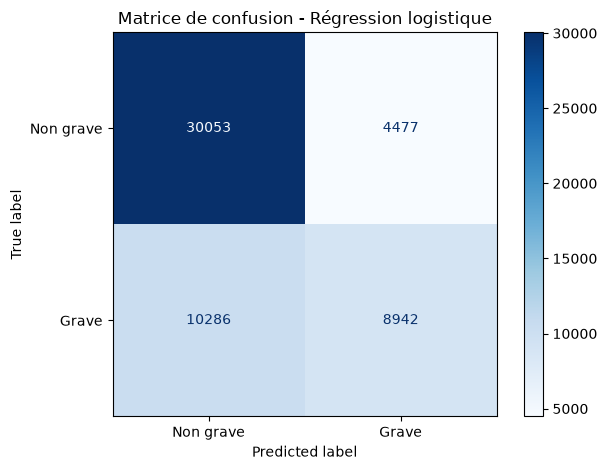

In [266]:
# 8.2 - Matrice de confusion

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Création et affichage de la matrice
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_logistique,
    display_labels=["Non grave", "Grave"],
    cmap="Blues",
    values_format="d"
)

plt.title("Matrice de confusion - Régression logistique")
plt.tight_layout()
plt.show()

In [267]:
# 8.3 - Rapport détaillé de classification

from sklearn.metrics import classification_report

print("Rapport de classification - Régression logistique :\n")

print(
    classification_report(
        y_test,
        y_pred_logistique,
        target_names=["Non grave", "Grave"],
        digits=3
    )
)

Rapport de classification - Régression logistique :

              precision    recall  f1-score   support

   Non grave      0.745     0.870     0.803     34530
       Grave      0.666     0.465     0.548     19228

    accuracy                          0.725     53758
   macro avg      0.706     0.668     0.675     53758
weighted avg      0.717     0.725     0.712     53758



In [268]:
# 9.1 - Création du modèle Random Forest

from sklearn.ensemble import RandomForestClassifier

modele_foret = Pipeline(steps=[
    ("pretraitement", preprocesseur),
    ("classification", RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

print("Modèle Random Forest créé avec succès.")

Modèle Random Forest créé avec succès.


In [269]:
# 9.2 - Entraînement du modèle Random Forest

modele_foret.fit(X_train, y_train)

print("Entraînement du Random Forest terminé avec succès.")

Entraînement du Random Forest terminé avec succès.


In [270]:
# 9.3 - Prédictions du Random Forest

y_pred_foret = modele_foret.predict(X_test)

y_proba_foret = modele_foret.predict_proba(X_test)[:, 1]

print("Nombre de prédictions :", len(y_pred_foret))

print("\nRépartition des classes prédites :")
print(pd.Series(y_pred_foret).value_counts().sort_index())

Nombre de prédictions : 53758

Répartition des classes prédites :
0    33704
1    20054
Name: count, dtype: int64


In [271]:
# 9.4 - Évaluation du Random Forest

accuracy_foret = accuracy_score(y_test, y_pred_foret)
precision_foret = precision_score(y_test, y_pred_foret)
rappel_foret = recall_score(y_test, y_pred_foret)
f1_foret = f1_score(y_test, y_pred_foret)
roc_auc_foret = roc_auc_score(y_test, y_proba_foret)

print("Performances du Random Forest :")
print(f"Accuracy  : {accuracy_foret:.2%}")
print(f"Précision : {precision_foret:.2%}")
print(f"Rappel    : {rappel_foret:.2%}")
print(f"F1-score  : {f1_foret:.2%}")
print(f"ROC-AUC   : {roc_auc_foret:.4f}")

print("\nRapport de classification :")
print(classification_report(
    y_test,
    y_pred_foret,
    target_names=["Non grave", "Grave"],
    digits=3
))

Performances du Random Forest :
Accuracy  : 71.90%
Précision : 60.28%
Rappel    : 62.87%
F1-score  : 61.55%
ROC-AUC   : 0.7641

Rapport de classification :
              precision    recall  f1-score   support

   Non grave      0.788     0.769     0.779     34530
       Grave      0.603     0.629     0.615     19228

    accuracy                          0.719     53758
   macro avg      0.696     0.699     0.697     53758
weighted avg      0.722     0.719     0.720     53758



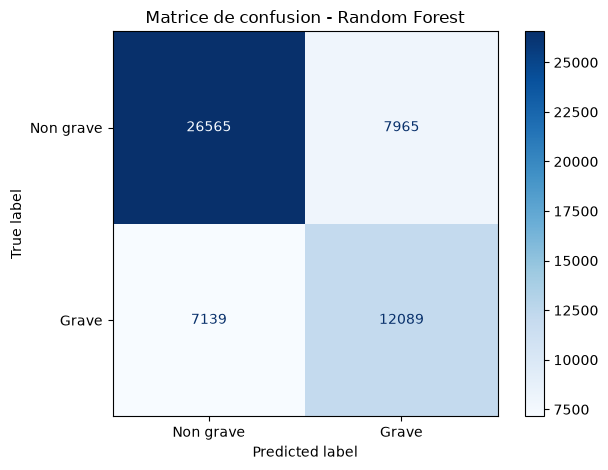

In [272]:
# 9.5 - Matrice de confusion du Random Forest

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_foret,
    display_labels=["Non grave", "Grave"],
    cmap="Blues",
    values_format="d"
)

plt.title("Matrice de confusion - Random Forest")
plt.tight_layout()
plt.show()

## 10. Comparaison des modèles

In [273]:
# 10.1 - Comparaison des performances des modèles

comparaison_modeles = pd.DataFrame({
    "Modèle": ["Régression logistique", "Random Forest"],
    "Accuracy": [accuracy_logistique, accuracy_foret],
    "Précision": [precision_logistique, precision_foret],
    "Rappel": [rappel_logistique, rappel_foret],
    "F1-score": [f1_logistique, f1_foret],
    "ROC-AUC": [roc_auc_logistique, roc_auc_foret]
})

# Afficher les performances en pourcentage
display(
    comparaison_modeles.style.format({
        "Accuracy": "{:.2%}",
        "Précision": "{:.2%}",
        "Rappel": "{:.2%}",
        "F1-score": "{:.2%}",
        "ROC-AUC": "{:.2%}"
    })
)

,Modèle,Accuracy,Précision,Rappel,F1-score,ROC-AUC
0,Régression logistique,72.54%,66.64%,46.51%,54.78%,75.23%
1,Random Forest,71.90%,60.28%,62.87%,61.55%,76.41%


## 11. Optimisation du seuil de classification

In [274]:
# 11.1 - Comparaison des seuils de classification

import numpy as np

# Seuils à tester
seuils = np.arange(0.20, 0.81, 0.05)

resultats_seuils = []

for seuil in seuils:

    # Transformer les probabilités en prédictions 0 ou 1
    predictions = (y_proba_foret >= seuil).astype(int)

    # Calculer les indicateurs pour la classe grave
    resultats_seuils.append({
        "Seuil": round(float(seuil), 2),
        "Précision": precision_score(y_test, predictions, zero_division=0),
        "Rappel": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0)
    })

# Construire le tableau des résultats
tableau_seuils = pd.DataFrame(resultats_seuils)

display(
    tableau_seuils.style.format({
        "Seuil": "{:.2f}",
        "Précision": "{:.2%}",
        "Rappel": "{:.2%}",
        "F1-score": "{:.2%}"
    })
)

,Seuil,Précision,Rappel,F1-score
0,0.20,37.14%,99.14%,54.04%
1,0.25,39.53%,96.77%,56.14%
2,0.30,42.96%,92.11%,58.59%
3,0.35,47.05%,85.44%,60.69%
4,0.40,50.86%,79.29%,61.97%
5,0.45,56.05%,70.45%,62.43%
6,0.50,60.28%,62.87%,61.55%
7,0.55,63.19%,56.60%,59.71%
8,0.60,67.32%,49.37%,56.96%
9,0.65,69.19%,44.47%,54.14%


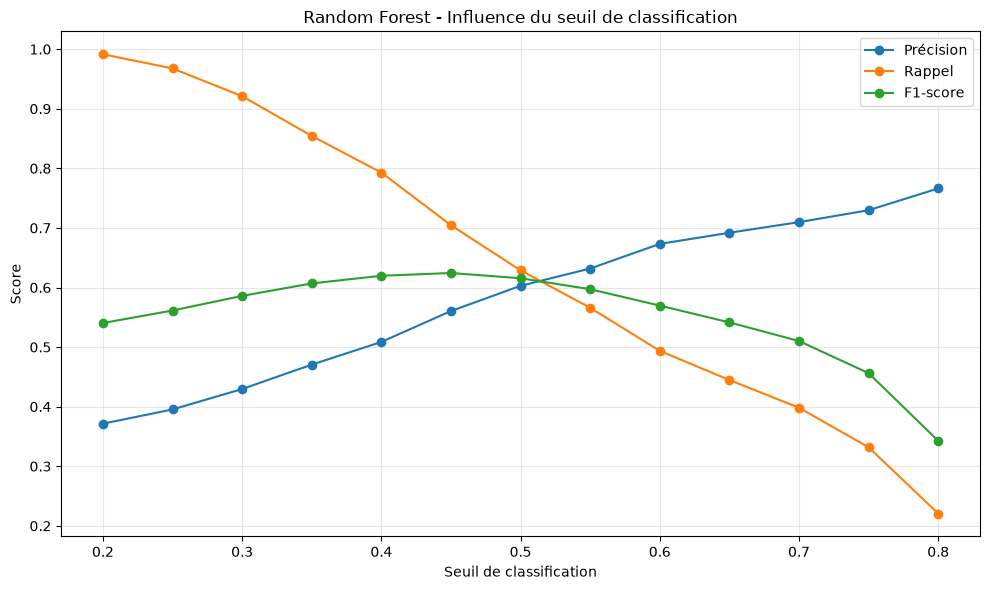

In [275]:
# 11.2 - Visualisation des performances selon le seuil

plt.figure(figsize=(10, 6))

plt.plot(
    tableau_seuils["Seuil"],
    tableau_seuils["Précision"],
    marker="o",
    label="Précision"
)

plt.plot(
    tableau_seuils["Seuil"],
    tableau_seuils["Rappel"],
    marker="o",
    label="Rappel"
)

plt.plot(
    tableau_seuils["Seuil"],
    tableau_seuils["F1-score"],
    marker="o",
    label="F1-score"
)

plt.xlabel("Seuil de classification")
plt.ylabel("Score")
plt.title("Random Forest - Influence du seuil de classification")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [276]:
# 11.3 - Identifier le seuil ayant le meilleur F1-score

meilleur_resultat = tableau_seuils.loc[
    tableau_seuils["F1-score"].idxmax()
]

print("Meilleur seuil testé :", meilleur_resultat["Seuil"])
print(f"Précision : {meilleur_resultat['Précision']:.2%}")
print(f"Rappel    : {meilleur_resultat['Rappel']:.2%}")
print(f"F1-score  : {meilleur_resultat['F1-score']:.2%}")

Meilleur seuil testé : 0.45
Précision : 56.05%
Rappel    : 70.45%
F1-score  : 62.43%


## 12. Validation et optimisation du modèle

### 12.1. Création d'un jeu de validation

Le jeu d'entraînement est subdivisé en deux parties :
- 80 % pour l'apprentissage ;
- 20 % pour la validation.

Le jeu de test initial reste réservé à l'évaluation finale.

## 12. Validation et optimisation du modèle

### 12.1. Création d'un jeu de validation

Le jeu d'entraînement est subdivisé en deux parties :
- 80 % pour l'apprentissage ;
- 20 % pour la validation.

Le jeu de test initial reste réservé à l'évaluation finale.

In [ ]:
# 12.1 - Création des jeux d'apprentissage et de validation

X_train_final, X_validation, y_train_final, y_validation = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Vérification des dimensions
print("Apprentissage :", X_train_final.shape)
print("Validation    :", X_validation.shape)
print("Test conservé :", X_test.shape)

# Vérification de la proportion d'accidents graves
print("\nProportion d'accidents graves :")
print(f"Apprentissage : {y_train_final.mean():.2%}")
print(f"Validation    : {y_validation.mean():.2%}")
print(f"Test          : {y_test.mean():.2%}")

Apprentissage : (172024, 14)
Validation    : (43006, 14)
Test conservé : (53758, 14)

Proportion d'accidents graves :
Apprentissage : 35.77%
Validation    : 35.77%
Test          : 35.77%


In [ ]:
# 12.2 - Contrôle de l'absence de chevauchement

chevauchement_train_validation = (
    X_train_final.index.intersection(X_validation.index)
)

chevauchement_train_test = (
    X_train_final.index.intersection(X_test.index)
)

chevauchement_validation_test = (
    X_validation.index.intersection(X_test.index)
)

print("Chevauchement apprentissage / validation :",
      len(chevauchement_train_validation))

print("Chevauchement apprentissage / test :",
      len(chevauchement_train_test))

print("Chevauchement validation / test :",
      len(chevauchement_validation_test))

Chevauchement apprentissage / validation : 0
Chevauchement apprentissage / test : 0
Chevauchement validation / test : 0


In [ ]:
# 12.3 - Réentraînement du Random Forest sur le jeu d'apprentissage

from sklearn.base import clone

# Créer une copie indépendante du pipeline Random Forest existant
modele_rf_validation = clone(modele_foret)

# Entraîner le modèle uniquement sur les données d'apprentissage
modele_rf_validation.fit(X_train_final, y_train_final)

# Vérification
print("Random Forest réentraîné avec succès.")
print("Accidents utilisés :", len(X_train_final))

Random Forest réentraîné avec succès.
Accidents utilisés : 172024


In [ ]:
# 12.4 - Prédictions sur le jeu de validation

# Probabilité estimée pour la classe "accident grave"
y_proba_validation = modele_rf_validation.predict_proba(
    X_validation
)[:, 1]

# Prédiction avec le seuil standard de 0.50
y_pred_validation = (y_proba_validation >= 0.50).astype(int)

print("Nombre de prédictions :", len(y_pred_validation))
print("Accidents prédits graves :", y_pred_validation.sum())

Nombre de prédictions : 43006
Accidents prédits graves : 16192


In [ ]:
# 12.5 - Comparaison des seuils sur le jeu de validation

import numpy as np
import pandas as pd

from sklearn.metrics import precision_score, recall_score, f1_score

resultats_validation = []

# Tester les seuils de 0.20 à 0.80
for seuil in np.arange(0.20, 0.81, 0.05):

    # Transformer les probabilités en classes prédites
    predictions = (y_proba_validation >= seuil).astype(int)

    # Calculer les performances pour les accidents graves
    resultats_validation.append({
        "Seuil": round(float(seuil), 2),
        "Précision": precision_score(y_validation, predictions, zero_division=0),
        "Rappel": recall_score(y_validation, predictions, zero_division=0),
        "F1-score": f1_score(y_validation, predictions, zero_division=0)
    })

# Construire le tableau comparatif
tableau_validation = pd.DataFrame(resultats_validation)

# Identifier le meilleur seuil selon le F1-score
meilleur_resultat_validation = tableau_validation.loc[
    tableau_validation["F1-score"].idxmax()
]

seuil_optimal = float(meilleur_resultat_validation["Seuil"])

display(tableau_validation.round(4))

print("\nMeilleur seuil sur la validation :", seuil_optimal)
print(f"Précision : {meilleur_resultat_validation['Précision']:.2%}")
print(f"Rappel    : {meilleur_resultat_validation['Rappel']:.2%}")
print(f"F1-score  : {meilleur_resultat_validation['F1-score']:.2%}")

,Seuil,Précision,Rappel,F1-score
0,0.20,0.3711,0.9914,0.5400
1,0.25,0.3937,0.9711,0.5602
2,0.30,0.4310,0.9264,0.5883
3,0.35,0.4732,0.8591,0.6103
4,0.40,0.5124,0.7976,0.6240
5,0.45,0.5563,0.7190,0.6272
6,0.50,0.6046,0.6365,0.6201
7,0.55,0.6349,0.5784,0.6053
8,0.60,0.6753,0.5015,0.5756
9,0.65,0.6948,0.4454,0.5428



Meilleur seuil sur la validation : 0.45
Précision : 55.63%
Rappel    : 71.90%
F1-score  : 62.72%


### 12.6. Réentraînement final du Random Forest

Après avoir sélectionné le seuil de classification sur le jeu
de validation, nous réentraînons le Random Forest sur l'ensemble
des données d'entraînement initiales.

Le jeu de test reste indépendant et n'a pas été utilisé
pour choisir le seuil de classification.

In [ ]:
# 12.6 - Réentraînement final du Random Forest

from sklearn.base import clone

# Créer une nouvelle copie du modèle Random Forest
modele_rf_final = clone(modele_foret)

# Entraîner sur l'ensemble d'entraînement initial
# (apprentissage + validation)
modele_rf_final.fit(X_train, y_train)

# Conserver le seuil sélectionné sur la validation
seuil_final = 0.45

# Vérification
print("Modèle final entraîné avec succès.")
print("Nombre d'accidents utilisés :", len(X_train))
print("Seuil retenu :", seuil_final)

Modèle final entraîné avec succès.
Nombre d'accidents utilisés : 215030
Seuil retenu : 0.45


In [ ]:
# 12.7 - Évaluation finale sur le jeu de test

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Calculer les probabilités d'accidents graves
y_proba_final = modele_rf_final.predict_proba(X_test)[:, 1]

# Appliquer le seuil retenu sur la validation
y_pred_final = (y_proba_final >= seuil_final).astype(int)

# Calculer les métriques finales
print("ÉVALUATION FINALE - RANDOM FOREST")
print("-" * 45)

print(f"Accuracy  : {accuracy_score(y_test, y_pred_final):.2%}")
print(f"Précision : {precision_score(y_test, y_pred_final):.2%}")
print(f"Rappel    : {recall_score(y_test, y_pred_final):.2%}")
print(f"F1-score  : {f1_score(y_test, y_pred_final):.2%}")
print(f"ROC-AUC   : {roc_auc_score(y_test, y_proba_final):.2%}")

print("\nRapport de classification :")
print(
    classification_report(
        y_test,
        y_pred_final,
        target_names=["Non grave", "Grave"],
        digits=3
    )
)

ÉVALUATION FINALE - RANDOM FOREST
---------------------------------------------
Accuracy  : 69.67%
Précision : 56.05%
Rappel    : 70.45%
F1-score  : 62.43%
ROC-AUC   : 76.41%

Rapport de classification :
              precision    recall  f1-score   support

   Non grave      0.808     0.692     0.746     34530
       Grave      0.561     0.705     0.624     19228

    accuracy                          0.697     53758
   macro avg      0.684     0.698     0.685     53758
weighted avg      0.719     0.697     0.702     53758



In [ ]:
### 12.8. Matrice de confusion finale

La matrice de confusion permet de visualiser les prédictions
correctes et incorrectes du Random Forest sur le jeu de test.

Une attention particulière est portée aux faux négatifs,
c'est-à-dire aux accidents réellement graves que le modèle
classe à tort comme non graves.

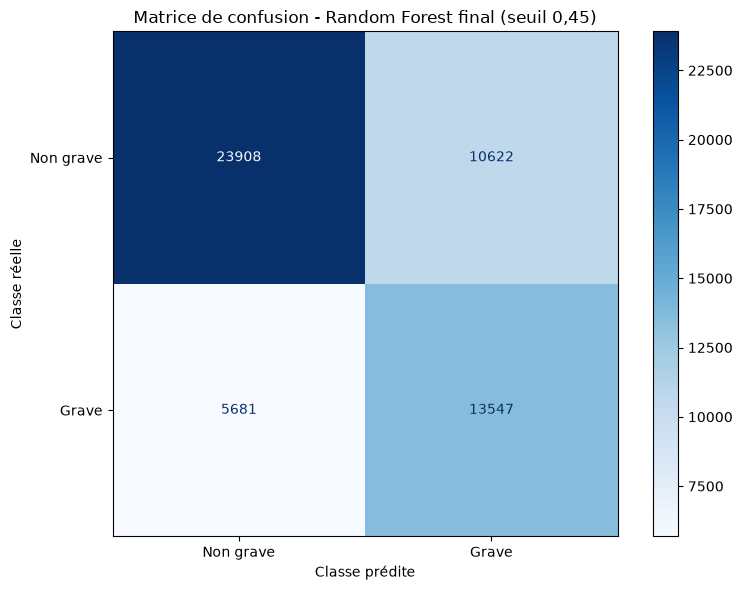

In [ ]:
# 12.8 - Matrice de confusion finale du Random Forest

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Créer la matrice de confusion à partir des prédictions finales
fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_final,
    labels=[0, 1],
    display_labels=["Non grave", "Grave"],
    cmap="Blues",
    values_format="d",
    ax=ax
)

# Personnaliser le graphique
ax.set_title(
    "Matrice de confusion - Random Forest final (seuil 0,45)"
)

ax.set_xlabel("Classe prédite")
ax.set_ylabel("Classe réelle")

plt.tight_layout()
plt.show()

In [ ]:
# 12.9 - Analyse des erreurs de classification

from sklearn.metrics import confusion_matrix

# Récupérer les quatre valeurs de la matrice
tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_pred_final,
    labels=[0, 1]
).ravel()

print("ANALYSE DES PRÉDICTIONS FINALES")
print("-" * 45)

print("Vrais négatifs :", tn)
print("Faux positifs  :", fp)
print("Faux négatifs  :", fn)
print("Vrais positifs :", tp)

print("\nAccidents graves réellement présents :", tp + fn)
print("Accidents graves correctement détectés :", tp)

print(
    "Taux d'accidents graves non détectés :",
    f"{fn / (tp + fn):.2%}"
)

ANALYSE DES PRÉDICTIONS FINALES
---------------------------------------------
Vrais négatifs : 23908
Faux positifs  : 10622
Faux négatifs  : 5681
Vrais positifs : 13547

Accidents graves réellement présents : 19228
Accidents graves correctement détectés : 13547
Taux d'accidents graves non détectés : 29.55%


## 13. Interprétation du modèle Random Forest

### 13.1. Importance des variables explicatives

L'objectif est d'identifier les caractéristiques qui contribuent
le plus aux prédictions de gravité des accidents routiers.

Nous utilisons l'importance par permutation sur le jeu de
validation, afin de mesurer la diminution des performances
lorsqu'une variable explicative est mélangée aléatoirement.

Cette analyse permet d'interpréter le modèle, mais ne démontre
pas une relation de causalité.

In [ ]:
# 13.2 - Importance des variables par permutation

from sklearn.inspection import permutation_importance
import pandas as pd

# Mesurer l'importance des variables sur le jeu de validation
importance_resultats = permutation_importance(
    modele_rf_validation,
    X_validation,
    y_validation,
    scoring="roc_auc",
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

# Construire un tableau récapitulatif
importance_variables = pd.DataFrame({
    "Variable": X_validation.columns,
    "Importance_moyenne": importance_resultats.importances_mean,
    "Ecart_type": importance_resultats.importances_std
})

# Classer les variables de la plus importante à la moins importante
importance_variables = (
    importance_variables
    .sort_values("Importance_moyenne", ascending=False)
    .reset_index(drop=True)
)

display(importance_variables)

,Variable,Importance_moyenne,Ecart_type
0,agglomeration,0.036154,0.000671
1,type_collision,0.035944,0.001170
2,categorie_route,0.029312,0.001126
3,regime_circulation,0.021788,0.001577
4,vitesse_max_autorisee,0.017652,0.000450
5,nombre_voies,0.010631,0.000427
6,intersection,0.004092,0.000064
7,trace_route,0.003403,0.000274
8,luminosite,0.003278,0.000183
9,conditions_atmospheriques,0.001567,0.000126


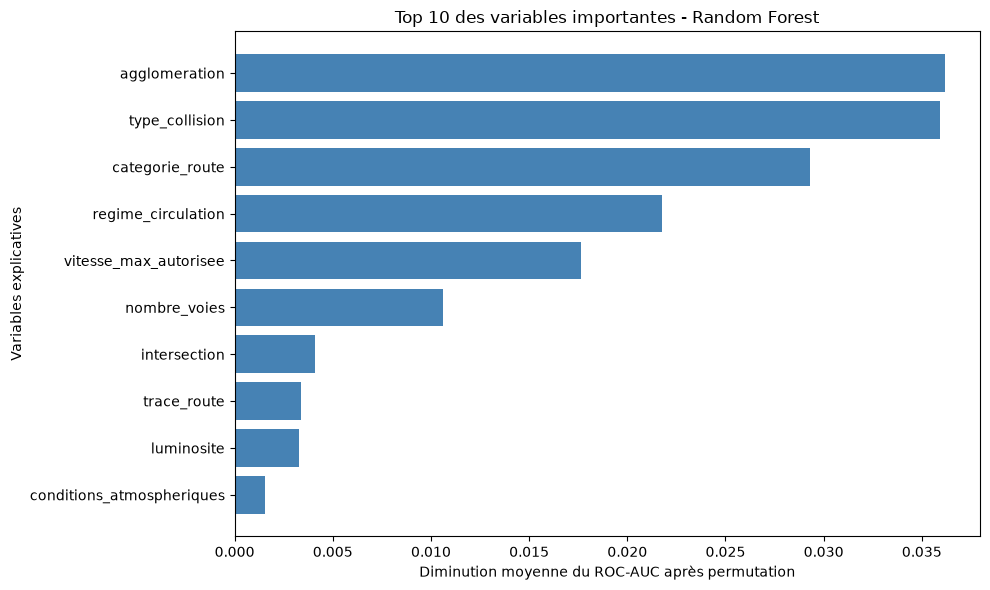

In [ ]:
# 13.3 - Graphique des 10 variables les plus importantes

import matplotlib.pyplot as plt

top_10 = importance_variables.head(10).sort_values(
    "Importance_moyenne"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_10["Variable"],
    top_10["Importance_moyenne"],
    color="steelblue"
)

plt.title("Top 10 des variables importantes - Random Forest")
plt.xlabel("Diminution moyenne du ROC-AUC après permutation")
plt.ylabel("Variables explicatives")

plt.tight_layout()
plt.show()

### 13.4. Interprétation métier des résultats

L'analyse de l'importance des variables par permutation montre que
les caractéristiques du contexte routier et du type de collision
jouent un rôle important dans les prédictions du Random Forest.

Les trois variables les plus influentes sont :

1. **L'agglomération** : elle contribue fortement à la capacité
   du modèle à distinguer les accidents graves des accidents
   non graves.

2. **Le type de collision** : les différentes configurations
   de collision apportent une information importante
   pour la classification.

3. **La catégorie de route** : les caractéristiques du réseau
   routier contribuent également à la prédiction de la gravité.

Le régime de circulation, la vitesse maximale autorisée et
le nombre de voies présentent aussi une contribution notable.

À l'inverse, la luminosité, les conditions atmosphériques
et le mois ont une importance prédictive plus limitée
dans le modèle étudié.

Ces résultats suggèrent que les caractéristiques de
l'environnement routier et des collisions constituent
des informations pertinentes pour l'analyse de la gravité.

**Limites d'interprétation :**

- L'importance des variables ne démontre pas une causalité.
- Elle ne précise pas quelles modalités augmentent ou diminuent
  la probabilité prédite d'un accident grave.
- Les variables corrélées peuvent partager leur importance.
- Les résultats dépendent des données et du modèle utilisés.

## 14. Bilan du Machine Learning

### 14.1. Résultats du modèle final

Le modèle Random Forest a été retenu pour la classification
des accidents graves, avec un seuil de décision de 0,45
sélectionné sur un jeu de validation indépendant.

Sur le jeu de test de 53 758 accidents, il obtient :

| Indicateur | Résultat |
|---|---:|
| Accuracy | 69,67 % |
| Précision (grave) | 56,05 % |
| Rappel (grave) | 70,45 % |
| F1-score (grave) | 62,43 % |
| ROC-AUC | 76,41 % |

### 14.2. Analyse des erreurs

Parmi les 19 228 accidents graves du jeu de test :

- 13 547 ont été correctement identifiés.
- 5 681 n'ont pas été détectés.
- Le taux de faux négatifs parmi les accidents graves
  atteint 29,55 %.

Le modèle produit également 10 622 faux positifs.

### 14.3. Conclusion métier

Le Random Forest permet de repérer une majorité des accidents
graves à partir des caractéristiques disponibles.

Cependant, le nombre de faux négatifs et de faux positifs
montre que les performances restent perfectibles.

Le modèle peut servir de support à l'analyse des facteurs
associés à la gravité des accidents, mais ne doit pas être
considéré comme un outil de décision autonome.

### 14.4. Limites et perspectives

- Les données couvrent les années 2020 à 2024.
- L'évaluation actuelle repose sur une séparation aléatoire ;
  une validation temporelle serait utile pour tester
  la généralisation à des années futures.
- Les variables explicatives disponibles ne couvrent pas
  tous les facteurs susceptibles d'influencer la gravité.
- Une optimisation des hyperparamètres pourrait améliorer
  les performances.
- D'autres modèles de classification pourraient être comparés.
- Le choix du seuil pourrait être adapté au coût métier
  des faux négatifs et des faux positifs.

## 15. Sauvegarde du modèle final

### 15.1. Exportation du Random Forest

Le modèle Random Forest final est sauvegardé au format Joblib.

Cette sauvegarde contient le pipeline complet, comprenant
les transformations des variables et le classificateur.

Le seuil de classification sélectionné sur le jeu de validation
est également conservé pour permettre la réutilisation du modèle.

# 16 — Optimisation des hyperparamètres avec GridSearchCV

## 16.1 — Objectif

L'objectif est de rechercher une combinaison pertinente
d'hyperparamètres pour le modèle Random Forest.

GridSearchCV permet de tester plusieurs configurations
du modèle à l'aide d'une validation croisée.

L'optimisation sera réalisée uniquement sur les données
d'entraînement, afin de préserver l'indépendance du jeu de test.

Les performances obtenues seront ensuite comparées
à celles du modèle Random Forest déjà retenu.

Le modèle final sauvegardé précédemment ne sera pas modifié
pendant cette expérimentation.

In [ ]:
# 16.2 - Importation des outils pour l'optimisation

from sklearn.model_selection import GridSearchCV
from sklearn.base import clone

# Vérifier les objets disponibles dans le notebook
objets_requis = [
    "modele_foret",
    "X_train_final",
    "y_train_final"
]

for nom in objets_requis:
    print(f"{nom} :", "Disponible" if nom in globals() else "Absent")

modele_foret : Disponible
X_train_final : Disponible
y_train_final : Disponible


In [ ]:
# 16.3 - Préparation de la grille d'hyperparamètres

# Créer une copie indépendante du modèle Random Forest
modele_grid = clone(modele_foret)

# Afficher les hyperparamètres disponibles
print("Hyperparamètres disponibles :")
print(list(modele_grid.get_params().keys()))

Hyperparamètres disponibles :
['memory', 'steps', 'transform_input', 'verbose', 'pretraitement', 'classification', 'pretraitement__n_jobs', 'pretraitement__remainder', 'pretraitement__sparse_threshold', 'pretraitement__transformer_weights', 'pretraitement__transformers', 'pretraitement__verbose', 'pretraitement__verbose_feature_names_out', 'pretraitement__numerique', 'pretraitement__categoriel', 'pretraitement__numerique__memory', 'pretraitement__numerique__steps', 'pretraitement__numerique__transform_input', 'pretraitement__numerique__verbose', 'pretraitement__numerique__imputation', 'pretraitement__numerique__standardisation', 'pretraitement__numerique__imputation__add_indicator', 'pretraitement__numerique__imputation__copy', 'pretraitement__numerique__imputation__fill_value', 'pretraitement__numerique__imputation__keep_empty_features', 'pretraitement__numerique__imputation__missing_values', 'pretraitement__numerique__imputation__strategy', 'pretraitement__numerique__standardisation_

In [ ]:
# 16.4 - Identifier automatiquement les paramètres du Random Forest

parametres_disponibles = modele_grid.get_params()

def trouver_parametre(nom):
    correspondances = [
        cle for cle in parametres_disponibles
        if cle == nom or cle.endswith("__" + nom)
    ]

    if len(correspondances) != 1:
        raise ValueError(
            f"Paramètre {nom} introuvable ou ambigu : {correspondances}"
        )

    return correspondances[0]


param_grid = {
    trouver_parametre("n_estimators"): [100, 150],
    trouver_parametre("max_depth"): [10, 20],
    trouver_parametre("min_samples_leaf"): [2, 5]
}

print("Grille de recherche :")
print(param_grid)

Grille de recherche :
{'classification__n_estimators': [100, 150], 'classification__max_depth': [10, 20], 'classification__min_samples_leaf': [2, 5]}


In [ ]:
# 16.5 - Configuration de la recherche d'hyperparamètres

grid_search = GridSearchCV(
    estimator=modele_grid,
    param_grid=param_grid,
    scoring="f1",
    cv=3,
    n_jobs=2,
    verbose=1,
    refit=True
)

print("GridSearchCV configuré avec succès.")
print("Nombre de combinaisons : 8")
print("Nombre de plis : 3")

GridSearchCV configuré avec succès.
Nombre de combinaisons : 8
Nombre de plis : 3


In [278]:
# 16.6 - Recherche des meilleurs hyperparamètres

import time

# Enregistrer le début de l'entraînement
debut = time.time()

# Lancer la validation croisée sur les données d'entraînement
grid_search.fit(X_train_final, y_train_final)

# Calculer la durée totale
duree = time.time() - debut

print("\nRecherche terminée avec succès !")
print(f"Durée : {duree / 60:.2f} minutes")

Fitting 3 folds for each of 8 candidates, totalling 24 fits

Recherche terminée avec succès !
Durée : 7.72 minutes


In [ ]:
# 16.7 - Résultats de GridSearchCV

print("MEILLEURS HYPERPARAMÈTRES")
print("-" * 50)

for parametre, valeur in grid_search.best_params_.items():
    print(f"{parametre} : {valeur}")

print("\nMEILLEUR F1-SCORE EN VALIDATION CROISÉE")
print(f"{grid_search.best_score_:.2%}")

print("\nNombre de configurations testées :",
      len(grid_search.cv_results_["params"]))

MEILLEURS HYPERPARAMÈTRES
--------------------------------------------------
classification__max_depth : 20
classification__min_samples_leaf : 5
classification__n_estimators : 150

MEILLEUR F1-SCORE EN VALIDATION CROISÉE
62.10%

Nombre de configurations testées : 8


In [ ]:
# 16.8 - Tableau comparatif des configurations

import pandas as pd

resultats_grid = pd.DataFrame(grid_search.cv_results_)

colonnes_resultats = [
    "params",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]

comparaison_grid = (
    resultats_grid[colonnes_resultats]
    .sort_values("rank_test_score")
    .reset_index(drop=True)
)

display(comparaison_grid)

,params,mean_test_score,std_test_score,rank_test_score
0,"{'classification__max_depth': 20, 'classificat...",0.620986,0.001026,1
1,"{'classification__max_depth': 20, 'classificat...",0.620670,0.001233,2
2,"{'classification__max_depth': 20, 'classificat...",0.619954,0.000941,3
3,"{'classification__max_depth': 20, 'classificat...",0.619728,0.001127,4
4,"{'classification__max_depth': 10, 'classificat...",0.612439,0.001195,5
5,"{'classification__max_depth': 10, 'classificat...",0.612201,0.001321,6
6,"{'classification__max_depth': 10, 'classificat...",0.611877,0.001555,7
7,"{'classification__max_depth': 10, 'classificat...",0.611834,0.001241,8


### 16.9 — Évaluation du modèle optimisé

L'objectif est d'évaluer le meilleur modèle identifié par
GridSearchCV sur le jeu de test, afin de comparer ses performances
à celles du Random Forest précédemment retenu.

Les indicateurs étudiés sont :
- Accuracy
- Précision
- Rappel
- F1-score
- ROC-AUC

La comparaison sera réalisée sur le même jeu de test,
avec une attention particulière portée à la détection
des accidents graves.

In [ ]:
# 16.10 - Évaluation du meilleur modèle GridSearchCV

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Récupérer le meilleur modèle entraîné
meilleur_modele_grid = grid_search.best_estimator_

# Calculer les probabilités d'accidents graves
proba_grid = meilleur_modele_grid.predict_proba(X_test)[:, 1]

# Appliquer le même seuil que le modèle final précédent
seuil_grid = 0.45
y_pred_grid = (proba_grid >= seuil_grid).astype(int)

# Afficher les performances
print("ÉVALUATION DU RANDOM FOREST OPTIMISÉ")
print("-" * 50)

print(f"Accuracy  : {accuracy_score(y_test, y_pred_grid):.2%}")
print(f"Précision : {precision_score(y_test, y_pred_grid):.2%}")
print(f"Rappel    : {recall_score(y_test, y_pred_grid):.2%}")
print(f"F1-score  : {f1_score(y_test, y_pred_grid):.2%}")
print(f"ROC-AUC   : {roc_auc_score(y_test, proba_grid):.2%}")

print("\nRapport de classification :")
print(
    classification_report(
        y_test,
        y_pred_grid,
        target_names=["Non grave", "Grave"]
    )
)

ÉVALUATION DU RANDOM FOREST OPTIMISÉ
--------------------------------------------------
Accuracy  : 69.44%
Précision : 55.68%
Rappel    : 71.27%
F1-score  : 62.52%
ROC-AUC   : 76.54%

Rapport de classification :
              precision    recall  f1-score   support

   Non grave       0.81      0.68      0.74     34530
       Grave       0.56      0.71      0.63     19228

    accuracy                           0.69     53758
   macro avg       0.68      0.70      0.68     53758
weighted avg       0.72      0.69      0.70     53758



### 16.11 — Comparaison du modèle initial et du modèle optimisé

Cette étape compare les performances des deux modèles Random Forest
sur le même jeu de test, en utilisant le même seuil de classification
de 0,45.

L'objectif est d'évaluer si l'optimisation des hyperparamètres
apporte une amélioration réelle des performances.

In [ ]:
# 16.12 - Tableau comparatif des performances

import pandas as pd

comparaison_modeles = pd.DataFrame({
    "Indicateur": [
        "Accuracy",
        "Précision",
        "Rappel",
        "F1-score",
        "ROC-AUC"
    ],
    "Random Forest initial": [
        0.6967,
        0.5605,
        0.7045,
        0.6243,
        0.7641
    ],
    "Random Forest optimisé": [
        accuracy_score(y_test, y_pred_grid),
        precision_score(y_test, y_pred_grid),
        recall_score(y_test, y_pred_grid),
        f1_score(y_test, y_pred_grid),
        roc_auc_score(y_test, proba_grid)
    ]
})

# Calculer la différence en points de pourcentage
comparaison_modeles["Écart (points)"] = (
    comparaison_modeles["Random Forest optimisé"]
    - comparaison_modeles["Random Forest initial"]
) * 100

# Afficher les résultats
display(
    comparaison_modeles.style.format({
        "Random Forest initial": "{:.2%}",
        "Random Forest optimisé": "{:.2%}",
        "Écart (points)": "{:+.2f}"
    })
)

,Indicateur,Random Forest initial,Random Forest optimisé,Écart (points)
0,Accuracy,69.67%,69.44%,-0.23
1,Précision,56.05%,55.68%,-0.37
2,Rappel,70.45%,71.27%,+0.82
3,F1-score,62.43%,62.52%,+0.09
4,ROC-AUC,76.41%,76.54%,+0.13


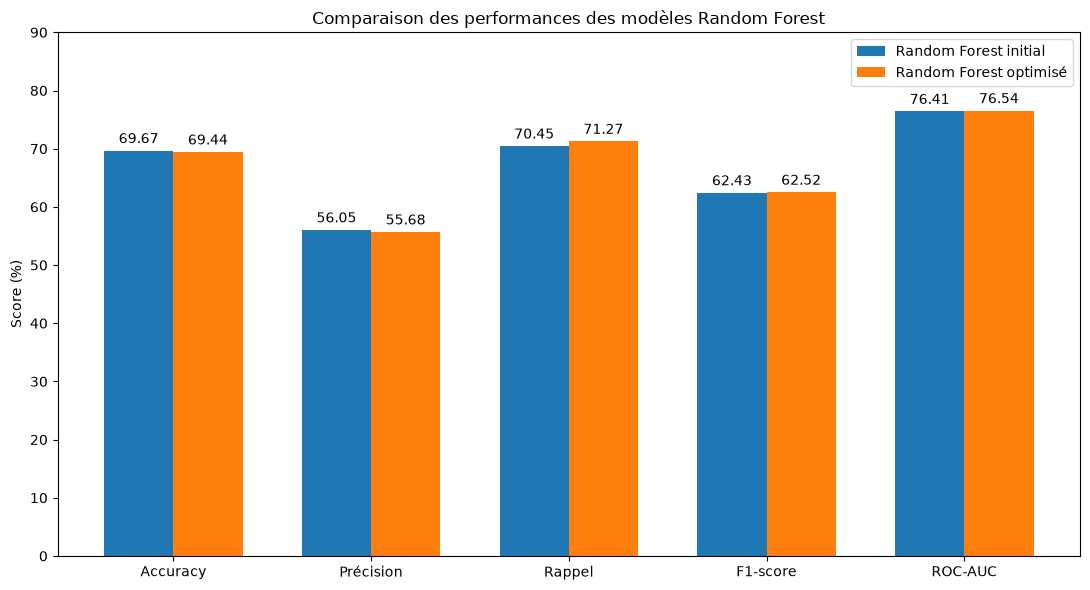

In [ ]:
# 16.13 - Graphique comparatif des performances

import matplotlib.pyplot as plt
import numpy as np

indicateurs = comparaison_modeles["Indicateur"]
scores_initial = comparaison_modeles["Random Forest initial"] * 100
scores_optimise = comparaison_modeles["Random Forest optimisé"] * 100

x = np.arange(len(indicateurs))
largeur = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

barres_initial = ax.bar(
    x - largeur / 2,
    scores_initial,
    largeur,
    label="Random Forest initial"
)

barres_optimise = ax.bar(
    x + largeur / 2,
    scores_optimise,
    largeur,
    label="Random Forest optimisé"
)

ax.set_title(
    "Comparaison des performances des modèles Random Forest"
)
ax.set_ylabel("Score (%)")
ax.set_xticks(x)
ax.set_xticklabels(indicateurs)
ax.set_ylim(0, 90)
ax.legend()

ax.bar_label(barres_initial, fmt="%.2f", padding=3)
ax.bar_label(barres_optimise, fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()

### 16.14 — Interprétation des résultats

L'optimisation des hyperparamètres du Random Forest avec
GridSearchCV a permis d'obtenir un F1-score de 62,52 % sur
le jeu de test, contre 62,43 % pour le modèle initial.

Le rappel progresse de 70,45 % à 71,27 %, ce qui signifie
que le modèle optimisé identifie une proportion légèrement
plus importante des accidents graves.

En revanche, la précision et l'accuracy diminuent légèrement.

L'amélioration globale reste limitée. Ces résultats ne
démontrent donc pas une supériorité importante du modèle
optimisé.

Dans une logique d'identification des accidents graves,
le rappel constitue un indicateur particulièrement important,
car les faux négatifs correspondent aux accidents graves
que le modèle ne détecte pas.

Le modèle optimisé peut ainsi être privilégié pour son
rappel légèrement supérieur, sous réserve de considérer
également les fausses alertes, les contraintes d'utilisation
et les limites de généralisation.

In [ ]:
# 16.15 - Analyse des erreurs du modèle optimisé

from sklearn.metrics import confusion_matrix

tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_pred_grid,
    labels=[0, 1]
).ravel()

print("ANALYSE DES ERREURS - RANDOM FOREST OPTIMISÉ")
print("-" * 55)

print(f"Vrais négatifs : {tn}")
print(f"Faux positifs  : {fp}")
print(f"Faux négatifs  : {fn}")
print(f"Vrais positifs : {tp}")

print(f"\nAccidents graves réellement présents : {tp + fn}")
print(f"Accidents graves correctement détectés : {tp}")

print(
    f"Taux d'accidents graves non détectés : "
    f"{fn / (tp + fn):.2%}"
)

ANALYSE DES ERREURS - RANDOM FOREST OPTIMISÉ
-------------------------------------------------------
Vrais négatifs : 23624
Faux positifs  : 10906
Faux négatifs  : 5524
Vrais positifs : 13704

Accidents graves réellement présents : 19228
Accidents graves correctement détectés : 13704
Taux d'accidents graves non détectés : 28.73%


### 16.16 — Sélection et justification du modèle final

Le modèle Random Forest optimisé avec GridSearchCV est retenu
comme modèle candidat final.

Les meilleurs hyperparamètres obtenus sont :

- `max_depth = 20`
- `min_samples_leaf = 5`
- `n_estimators = 150`

Sur le jeu de test, ce modèle obtient :

- Accuracy : 69,44 %
- Précision : 55,68 %
- Rappel : 71,27 %
- F1-score : 62,52 %
- ROC-AUC : 76,54 %

Le modèle optimisé présente un rappel légèrement supérieur
à celui du Random Forest initial.

Ce critère est particulièrement important pour notre objectif
d'identification des accidents graves.

Cependant, l'amélioration globale reste très limitée et ne
permet pas de conclure à une supériorité significative.

Le modèle est donc retenu comme candidat pour la suite
de l'analyse, et non comme outil opérationnel validé.

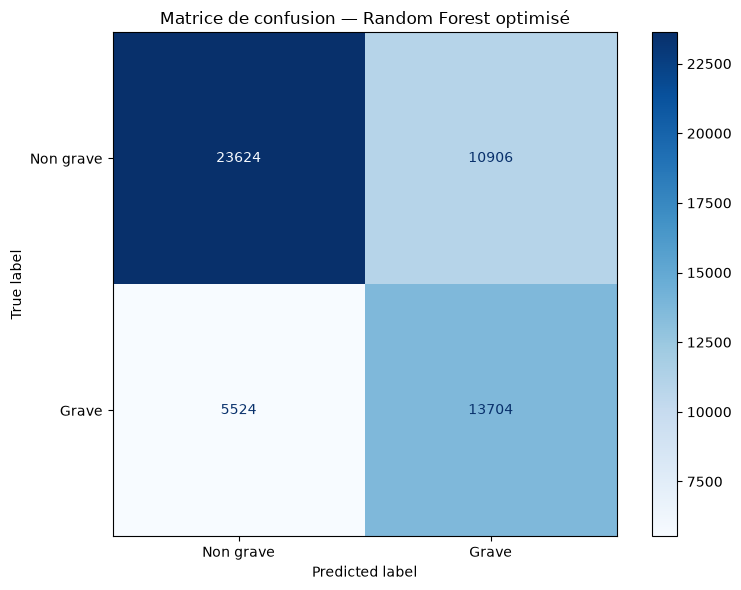

In [ ]:
# 16.17 - Matrice de confusion du Random Forest optimisé

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Construire la matrice de confusion
matrice = confusion_matrix(
    y_test,
    y_pred_grid,
    labels=[0, 1]
)

# Créer le graphique
fig, ax = plt.subplots(figsize=(8, 6))

affichage = ConfusionMatrixDisplay(
    confusion_matrix=matrice,
    display_labels=["Non grave", "Grave"]
)

affichage.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

ax.set_title(
    "Matrice de confusion — Random Forest optimisé"
)

plt.tight_layout()
plt.show()

### 16.18 — Premières limites du modèle

#### 1. Accidents graves non détectés

Le modèle ne détecte pas 5 524 accidents graves sur
les 19 228 présents dans le jeu de test, soit 28,73 %.

Ces faux négatifs représentent une limite importante
dans un contexte de sécurité routière.

#### 2. Fausses alertes

Le modèle classe 10 906 accidents non graves comme graves.

Ces faux positifs peuvent limiter la pertinence
d'une utilisation opérationnelle du modèle.

#### 3. Performances prédictives modérées

Le F1-score de 62,52 % montre que le modèle possède
une capacité de classification imparfaite.

Le ROC-AUC de 76,54 % indique une capacité de
discrimination intéressante, mais insuffisante
pour garantir des prédictions fiables dans tous les cas.

#### 4. Limites d'interprétation

Les résultats mettent en évidence des associations
statistiques entre les variables étudiées et la gravité.

Ils ne permettent pas d'établir des relations de causalité.

#### 5. Utilisation responsable

Le modèle doit être considéré comme un outil
d'analyse exploratoire et d'aide à la compréhension
des facteurs associés à la gravité.

Il ne doit pas être utilisé seul pour prendre
des décisions individuelles ou opérationnelles.

In [ ]:
# 16.19 - Comparaison des modèles avec un seuil de 0.45

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

# Définir le seuil commun aux deux modèles
seuil = 0.45

# Vérifier le seuil du modèle initial
print("Seuil du modèle initial :", seuil_final)
print("Seuil du modèle optimisé :", seuil)

# Calculer les probabilités du Random Forest optimisé
proba_grid = grid_search.best_estimator_.predict_proba(
    X_test
)[:, 1]

# Appliquer le seuil de 0.45 au modèle optimisé
y_pred_grid_045 = (proba_grid >= seuil).astype(int)

# Construire le tableau comparatif
resultats_comparaison = pd.DataFrame({
    "Indicateur": [
        "Accuracy",
        "Précision",
        "Rappel",
        "F1-score",
        "ROC-AUC"
    ],
    "Modèle initial (seuil 0.45)": [
        accuracy_score(y_test, y_pred_final),
        precision_score(y_test, y_pred_final),
        recall_score(y_test, y_pred_final),
        f1_score(y_test, y_pred_final),
        roc_auc_score(y_test, y_proba_final)
    ],
    "Modèle optimisé (seuil 0.45)": [
        accuracy_score(y_test, y_pred_grid_045),
        precision_score(y_test, y_pred_grid_045),
        recall_score(y_test, y_pred_grid_045),
        f1_score(y_test, y_pred_grid_045),
        roc_auc_score(y_test, proba_grid)
    ]
})

# Afficher les résultats en pourcentage
display(
    resultats_comparaison.style.format({
        "Modèle initial (seuil 0.45)": "{:.2%}",
        "Modèle optimisé (seuil 0.45)": "{:.2%}"
    })
)

Seuil du modèle initial : 0.45
Seuil du modèle optimisé : 0.45


,Indicateur,Modèle initial (seuil 0.45),Modèle optimisé (seuil 0.45)
0,Accuracy,69.67%,69.44%
1,Précision,56.05%,55.68%
2,Rappel,70.45%,71.27%
3,F1-score,62.43%,62.52%
4,ROC-AUC,76.41%,76.54%


### 16.20 — Bilan de l'optimisation des hyperparamètres

L'optimisation du Random Forest a été réalisée avec GridSearchCV,
en utilisant une validation croisée à 3 plis et 8 configurations
d'hyperparamètres, soit 24 ajustements.

Les meilleurs hyperparamètres identifiés sont :
- max_depth : 20
- min_samples_leaf : 5
- n_estimators : 150

Le meilleur F1-score obtenu en validation croisée est de 62,10 %.

Sur le jeu de test, avec un seuil de classification de 0,45,
le modèle optimisé atteint :
- Accuracy : 69,44 %
- Précision : 55,68 %
- Rappel : 71,27 %
- F1-score : 62,52 %
- ROC-AUC : 76,54 %

Par rapport au Random Forest initial, le modèle optimisé
améliore légèrement le rappel (+0,82 point), le F1-score
(+0,09 point) et le ROC-AUC (+0,13 point).

En revanche, la précision et l'accuracy diminuent légèrement.

Le Random Forest optimisé est retenu comme modèle candidat
pour sa capacité légèrement supérieure à détecter les accidents
graves.

Les résultats montrent néanmoins que les gains restent modestes
et que le modèle conserve des limites, notamment concernant
les accidents graves non détectés.

Ce modèle constitue un outil d'analyse prédictive exploratoire
et ne doit pas être utilisé seul pour prendre des décisions
de sécurité routière.

### 16.21 — Sauvegarde du modèle Random Forest optimisé

Le meilleur modèle identifié par GridSearchCV est sauvegardé
avec son seuil de classification et la liste des variables explicatives.

Cette sauvegarde permettra de réutiliser le modèle sans
relancer la recherche d'hyperparamètres.

In [ ]:
# 16.21 - Réentraînement et sauvegarde du Random Forest optimisé

import joblib
from pathlib import Path
from sklearn.base import clone

# 1. Recréer le modèle à partir du pipeline utilisé pour GridSearchCV
modele_optimise = clone(modele_grid)

# 2. Appliquer les meilleurs hyperparamètres trouvés précédemment
modele_optimise.set_params(
    classification__max_depth=20,
    classification__min_samples_leaf=5,
    classification__n_estimators=150
)

# 3. Entraîner une seule fois le modèle optimisé
modele_optimise.fit(X_train_final, y_train_final)

# 4. Conserver le seuil de classification
seuil_optimise = 0.45

# 5. Créer le dossier de sauvegarde
dossier_modeles = Path("modeles")
dossier_modeles.mkdir(parents=True, exist_ok=True)

# 6. Regrouper les informations nécessaires
modele_a_sauvegarder = {
    "pipeline": modele_optimise,
    "seuil": seuil_optimise,
    "variables": list(X_train_final.columns)
}

# 7. Sauvegarder le modèle
chemin_modele = dossier_modeles / "random_forest_optimise.joblib"

joblib.dump(modele_a_sauvegarder, chemin_modele)

# 8. Vérifier la sauvegarde
print("Modèle optimisé entraîné et sauvegardé avec succès.")
print("Emplacement :", chemin_modele.resolve())
print("Seuil retenu :", seuil_optimise)
print("Nombre de variables :", len(modele_a_sauvegarder["variables"]))

Modèle optimisé entraîné et sauvegardé avec succès.
Emplacement : C:\Users\nabil\OneDrive\Desktop\data analyst\S15 à la fin de formation\Projet_Final_Accidents_Routiers\modeles\random_forest_optimise.joblib
Seuil retenu : 0.45
Nombre de variables : 14


### 16.22 — Vérification du modèle sauvegardé

Cette étape consiste à recharger le modèle Random Forest optimisé
depuis le fichier Joblib, puis à vérifier que les prédictions
obtenues sont identiques à celles du modèle entraîné en mémoire.

Elle permet de contrôler la fiabilité de la sauvegarde
et la possibilité de réutiliser le modèle ultérieurement.

In [284]:
# 16.22 - Vérification du modèle sauvegardé

import numpy as np
import joblib

# 1. Recharger le fichier sauvegardé
modele_charge = joblib.load(chemin_modele)

# 2. Récupérer les éléments sauvegardés
pipeline_charge = modele_charge["pipeline"]
seuil_charge = modele_charge["seuil"]
variables_chargees = modele_charge["variables"]

# 3. Calculer les probabilités avec le modèle chargé
proba_chargees = pipeline_charge.predict_proba(
    X_test[variables_chargees]
)[:, 1]

# 4. Appliquer le seuil de classification
predictions_chargees = (
    proba_chargees >= seuil_charge
).astype(int)

# 5. Calculer les prédictions du modèle avant sauvegarde
proba_avant_sauvegarde = modele_optimise.predict_proba(
    X_test[variables_chargees]
)[:, 1]

predictions_avant_sauvegarde = (
    proba_avant_sauvegarde >= seuil_optimise
).astype(int)

# 6. Comparer les résultats
print("VÉRIFICATION DU MODÈLE SAUVEGARDÉ")
print("-" * 45)

print("Chargement réussi :", True)
print("Seuil chargé :", seuil_charge)
print("Nombre de variables :", len(variables_chargees))

print(
    "Probabilités identiques :",
    np.allclose(proba_chargees, proba_avant_sauvegarde)
)

print(
    "Prédictions identiques :",
    np.array_equal(
        predictions_chargees,
        predictions_avant_sauvegarde
    )
)

VÉRIFICATION DU MODÈLE SAUVEGARDÉ
---------------------------------------------
Chargement réussi : True
Seuil chargé : 0.45
Nombre de variables : 14
Probabilités identiques : True
Prédictions identiques : True


### 16.23 — Évaluation du modèle sauvegardé

Cette étape permet d'évaluer le modèle Random Forest optimisé
après son rechargement depuis le fichier Joblib.

Les performances sont calculées sur le jeu de test
à partir des prédictions obtenues avec le seuil de 0,45.

In [285]:
# 16.23 - Évaluation du modèle sauvegardé

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Calculer les métriques du modèle rechargé
accuracy = accuracy_score(y_test, predictions_chargees)
precision = precision_score(y_test, predictions_chargees)
rappel = recall_score(y_test, predictions_chargees)
f1 = f1_score(y_test, predictions_chargees)
roc_auc = roc_auc_score(y_test, proba_chargees)

# Calculer la matrice de confusion
tn, fp, fn, tp = confusion_matrix(
    y_test,
    predictions_chargees,
    labels=[0, 1]
).ravel()

# Afficher les résultats
print("ÉVALUATION DU MODÈLE FINAL SAUVEGARDÉ")
print("-" * 45)

print(f"Accuracy  : {accuracy:.2%}")
print(f"Précision : {precision:.2%}")
print(f"Rappel    : {rappel:.2%}")
print(f"F1-score  : {f1:.2%}")
print(f"ROC-AUC   : {roc_auc:.2%}")

print("\nANALYSE DES ACCIDENTS GRAVES")
print("-" * 45)

print("Accidents graves correctement détectés :", tp)
print("Accidents graves non détectés :", fn)
print(f"Taux de non-détection : {fn / (tp + fn):.2%}")

ÉVALUATION DU MODÈLE FINAL SAUVEGARDÉ
---------------------------------------------
Accuracy  : 69.44%
Précision : 55.68%
Rappel    : 71.27%
F1-score  : 62.52%
ROC-AUC   : 76.54%

ANALYSE DES ACCIDENTS GRAVES
---------------------------------------------
Accidents graves correctement détectés : 13704
Accidents graves non détectés : 5524
Taux de non-détection : 28.73%


## 16.24 — Conclusion générale du Machine Learning

### Objectif du projet

L'objectif de cette modélisation était d'étudier la capacité
des algorithmes de Machine Learning à identifier les accidents
routiers présentant des conséquences graves, à partir des
données BAAC 2020-2024.

### Modèle retenu

Le modèle candidat final est un Random Forest optimisé
à l'aide de GridSearchCV.

L'optimisation a porté sur 8 configurations d'hyperparamètres,
évaluées par validation croisée à 3 plis.

Les meilleurs hyperparamètres obtenus sont :

- n_estimators : 150
- max_depth : 20
- min_samples_leaf : 5

Le seuil de classification retenu est de 0,45.

### Performances sur le jeu de test

| Indicateur | Résultat |
|---|---:|
| Accuracy | 69,44 % |
| Précision | 55,68 % |
| Rappel | 71,27 % |
| F1-score | 62,52 % |
| ROC-AUC | 76,54 % |

### Interprétation des résultats

Sur les 19 228 accidents graves présents dans le jeu de test :

- 13 704 ont été correctement identifiés.
- 5 524 n'ont pas été détectés.
- Le taux de non-détection atteint 28,73 %.

Le modèle détecte donc environ 7 accidents graves sur 10.

Le rappel est particulièrement important dans cette étude,
car un faux négatif correspond à un accident grave que le
modèle classe à tort comme non grave.

### Apport de l'optimisation

L'optimisation améliore légèrement le rappel, le F1-score
et le ROC-AUC par rapport au Random Forest initial.

Cependant, les gains restent modestes et s'accompagnent
d'une légère diminution de la précision et de l'accuracy.

### Limites

Les performances restent insuffisantes pour utiliser ce modèle
comme système autonome de décision en sécurité routière.

Les résultats doivent être interprétés comme une analyse
prédictive exploratoire et non comme une prédiction certaine
de la gravité d'un accident.

### Sauvegarde et reproductibilité

Le modèle optimisé a été sauvegardé au format Joblib,
avec un seuil de classification de 0,45 et 14 variables
explicatives.

Le rechargement a été vérifié avec succès :
les probabilités et les prédictions obtenues sont identiques
à celles du modèle avant sauvegarde.

### Conclusion

Cette étape complète l'analyse descriptive et les tableaux
de bord du projet par une approche prédictive.

Elle démontre l'intérêt du Machine Learning pour identifier
des situations associées à une gravité élevée, tout en
mettant en évidence les limites de cette approche.

## 17 — Vérification finale et reproductibilité

### 17.1 — Contrôle des fichiers du projet

Cette vérification permet de confirmer que les modèles
et les fichiers nécessaires à leur réutilisation sont présents.

In [286]:

# 17.1 - Vérification du fichier du modèle final

from pathlib import Path

# Définir le chemin du modèle optimisé retenu
chemin_modele_final = Path("modeles/random_forest_optimise.joblib")

# Vérifier que le fichier existe
print("VÉRIFICATION DU MODÈLE FINAL")
print("-" * 45)

print("Fichier :", chemin_modele_final)
print("Existe :", chemin_modele_final.is_file())

# Afficher sa taille si le fichier existe
if chemin_modele_final.is_file():
    taille_mo = chemin_modele_final.stat().st_size / (1024 ** 2)
    print(f"Taille : {taille_mo:.2f} Mo")
else:
    print("ATTENTION : le fichier du modèle final est introuvable.")


VÉRIFICATION DU MODÈLE FINAL
---------------------------------------------
Fichier : modeles\random_forest_optimise.joblib
Existe : True
Taille : 77.02 Mo


In [282]:
# 17.2 - Contrôle du contenu du modèle sauvegardé

import joblib

modele_charge = joblib.load(
    "modeles/random_forest_optimise.joblib"
)

print("Type du fichier :", type(modele_charge))

if isinstance(modele_charge, dict):
    print("\nInformations disponibles :")
    for cle in modele_charge.keys():
        print("-", cle)

Type du fichier : <class 'dict'>

Informations disponibles :
- pipeline
- seuil
- variables



### 17.3 — Conclusion de la vérification des modèles

Le Random Forest optimisé avec GridSearchCV est retenu comme modèle final du projet.

La sauvegarde, le rechargement et la cohérence des prédictions ont été vérifiés dans la section 16.

Le modèle final est enregistré dans le fichier `modeles/random_forest_optimise.joblib`.

Cette vérification confirme que le modèle sauvegardé peut être rechargé et réutilisé sans modifier les résultats des prédictions.
